# 07 - Ancient track: modern Balkans in a 1st-millennium CE context

This notebook is deliberately **separate** from the modern analysis. It puts
the modern samples next to ancient Balkan genomes, using data from the 2023
Cell paper "A Genetic History of the Balkans from Roman Frontier to Slavic
Migrations" (Olalde, Carrion et al., doi:10.1016/j.cell.2023.10.018; raw data
at ENA PRJEB66422, 1240k genotypes redistributed in AADR v66.p1).

Two things change when ancient DNA enters the picture:

1. Ancient genotypes are usually **pseudo-haploid** (one allele sampled per
   site) and have high missingness. They are not directly comparable to
   diploid modern genotypes at the individual level.
2. Ancient individuals cannot be clustered together with moderns into one
   "population"; they are used as **projected datapoints** on a modern
   reference, which is what the original paper does.

Here we do the simplest version: a joint PCA with mean imputation, plus a
zoom into the Balkan cline. Treat the ancient positions as approximate.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import poreklo_io as pio

FIG = ROOT / "results" / "figures"
NB07 = ROOT / "data" / "processed" / "nb07"
NB07.mkdir(parents=True, exist_ok=True)
MODERN = ROOT / "data" / "processed" / "modern_merged"
ANCIENT = ROOT / "data" / "ancient" / "aadr_ancient_balkans"
ancient_meta = pd.read_csv(ROOT / "data" / "metadata" / "aadr_ancient_balkans_samples.tsv", sep="\t")
modern_meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
print("ancient samples:", len(ancient_meta), " modern samples:", len(modern_meta))

ancient samples: 679  modern samples: 2374


## 1. Group the ancients into broad periods

AADR labels encode context, e.g. `Croatia_EIA` (Early Iron Age),
`Serbia_ImperialRoman`, `Croatia_EarlyMedieval_Avar`. We map the main ones
into four coarse period buckets for plotting. Anything unmapped stays grey.

In [2]:
def period(label: str) -> str | None:
    if "ImperialRoman" in label or label.endswith("_Roman") or "_Roman-" in label:
        return "Roman Imperial"
    if "LateAntiquity" in label or "MigrationPeriod" in label or "Gepids" in label or "Avar" in label:
        return "Late Antiquity / Migration"
    if "EarlyMedieval" in label or "Byzantine" in label or "EarlySlav" in label:
        return "Early Medieval"
    if "Medieval" in label or "PostMedieval" in label or "Ottoman" in label:
        return "Later Medieval"
    if any(token in label for token in ["_EIA", "_LIA", "_MIA", "_IA", "_BA", "_LBA", "_MBA", "_EBA", "_C_", "_C-", "_MN", "_LN", "_EN"]):
        return "Neolithic / Bronze / Iron Age"
    return None

ancient_meta["period"] = ancient_meta["group"].map(period)
print(ancient_meta["period"].value_counts(dropna=False).to_dict())

{'Neolithic / Bronze / Iron Age': 271, nan: 159, 'Roman Imperial': 128, 'Late Antiquity / Migration': 72, 'Later Medieval': 27, 'Early Medieval': 22}


## 2. Combine with the modern reference and run PCA

The two datasets were built from the same site list, but from two different
AADR maps, so a few SNPs may disagree on which allele is REF/ALT. We align
them explicitly in Python: keep only SNPs present in both with identical
allele sets, and flip the ancient dosage where the A1 alleles differ. This is
the same kind of allele harmonisation every merge pipeline needs.

In [3]:
def run(cmd):
    print("$", " ".join(str(c) for c in cmd))
    result = subprocess.run([str(c) for c in cmd], cwd=ROOT, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout[-3000:]); print(result.stderr[-3000:])
        result.check_returncode()
    return result.stdout

modern_prefix = ROOT / "data" / "processed" / "nb01" / "analysis"
modern_fam = pio.read_fam(str(modern_prefix) + ".fam")
modern_bim = pio.read_bim(str(modern_prefix) + ".bim")
modern_dos = pio.read_bed_dosage(str(modern_prefix) + ".bed", len(modern_fam), len(modern_bim))

ancient_fam = pio.read_fam(str(ANCIENT) + ".fam")
ancient_bim = pio.read_bim(str(ANCIENT) + ".bim")
ancient_dos = pio.read_bed_dosage(str(ANCIENT) + ".bed", len(ancient_fam), len(ancient_bim))
ancient_row = {record["rsid"]: i for i, record in enumerate(ancient_bim)}

modern_rows, ancient_rows, flips, mismatched = [], [], 0, 0
for i, record in enumerate(modern_bim):
    j = ancient_row.get(record["rsid"])
    if j is None:
        continue
    other = ancient_bim[j]
    if {record["a1"], record["a2"]} != {other["a1"], other["a2"]}:
        mismatched += 1
        continue
    if record["a1"] != other["a1"]:
        flips += 1
    modern_rows.append(i)
    ancient_rows.append(j)
print(f"shared SNPs: {len(modern_rows):,}; allele mismatches dropped: {mismatched:,}; flips: {flips:,}")

modern_dos = modern_dos[modern_rows]
ancient_dos = ancient_dos[ancient_rows].copy()
flip_sites = np.array([modern_bim[i]["a1"] != ancient_bim[j]["a1"] for i, j in zip(modern_rows, ancient_rows)])
ancient_dos[flip_sites] = np.where(ancient_dos[flip_sites] >= 0, 2 - ancient_dos[flip_sites], ancient_dos[flip_sites])
combined_dos = np.concatenate([modern_dos, ancient_dos], axis=1)
combined_codes = pio.DOSAGE_TO_BED_CODE[(combined_dos + 1).astype(np.int8)]

pio.write_bed(NB07 / "combined.bed", combined_codes)
pio.write_bim(NB07 / "combined.bim", [modern_bim[i] for i in modern_rows])
pio.write_fam(NB07 / "combined.fam",
              [{"fid": s["fid"], "iid": s["iid"], "sex": s.get("sex", "0")} for s in modern_fam]
              + [{"fid": s["fid"], "iid": s["iid"], "sex": s.get("sex", "0")} for s in ancient_fam])

run(["plink2", "--bfile", NB07 / "combined", "--autosome", "--pca", "10", "approx", "meanimpute",
     "--seed", "42", "--out", NB07 / "pca"])

eigenvec = pd.read_csv(NB07 / "pca.eigenvec", sep=r"\s+").rename(columns={"#FID": "fid", "IID": "iid", "FID": "fid"})
meta_all = pd.concat([
    modern_meta.assign(kind="modern"),
    ancient_meta.assign(kind="ancient", source="aadr"),
], ignore_index=True)
df = eigenvec.merge(meta_all[["iid", "group", "kind", "period"]], on="iid", how="left")
print(df["kind"].value_counts().to_dict())

shared SNPs: 72,552; allele mismatches dropped: 0; flips: 0


$ plink2 --bfile ./data/processed/nb07/combined --autosome --pca 10 approx meanimpute --seed 42 --out ./data/processed/nb07/pca


{'modern': 2374, 'ancient': 679}


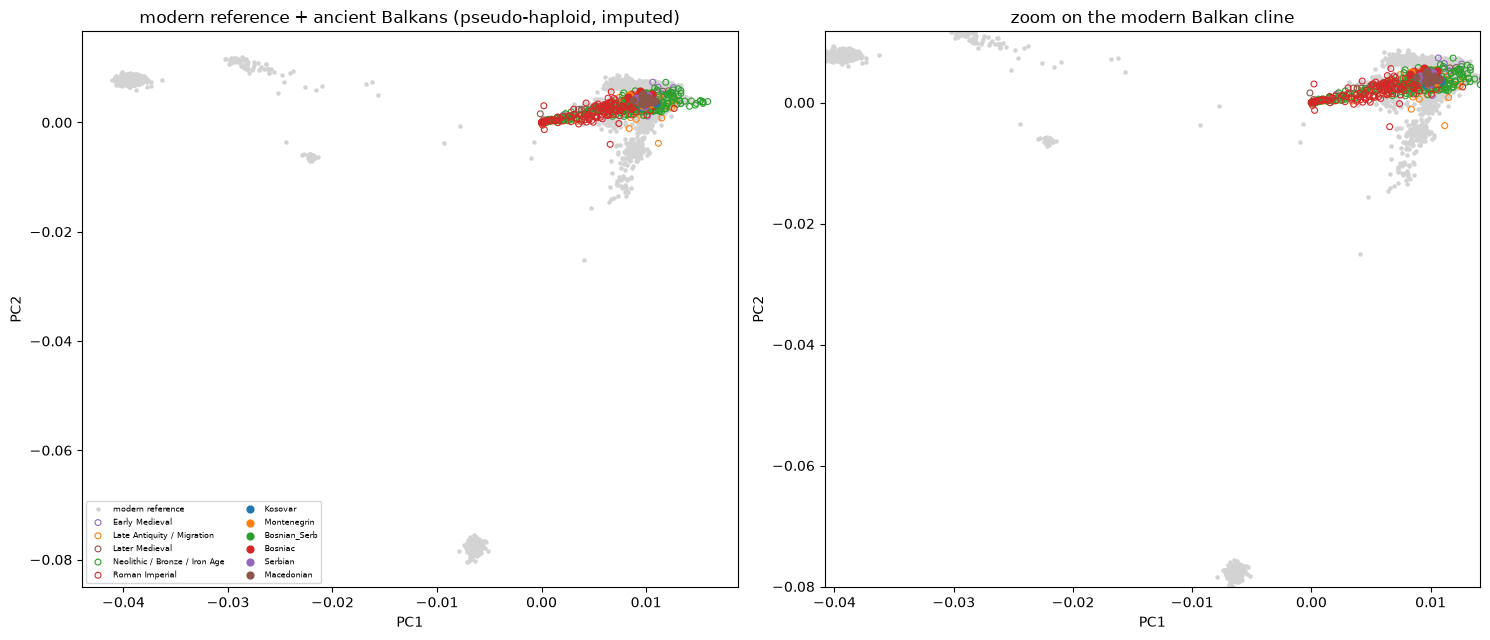

In [4]:
balkan = {"Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"}
period_colors = {
    "Neolithic / Bronze / Iron Age": "tab:green",
    "Roman Imperial": "tab:red",
    "Late Antiquity / Migration": "tab:orange",
    "Early Medieval": "tab:purple",
    "Later Medieval": "tab:brown",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
modern = df[df["kind"] == "modern"]
axes[0].scatter(modern["PC1"], modern["PC2"], s=5, c="lightgrey", label="modern reference")
for p, sub in df[df["kind"] == "ancient"].groupby("period"):
    axes[0].scatter(sub["PC1"], sub["PC2"], s=18, facecolors="none",
                    edgecolors=period_colors.get(p, "grey"), label=p, linewidths=0.8)
for g in balkan:
    sub = modern[modern["group"] == g]
    axes[0].scatter(sub["PC1"], sub["PC2"], s=24, label=g)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("modern reference + ancient Balkans (pseudo-haploid, imputed)")
axes[0].legend(fontsize=6, ncol=2)

axes[1].scatter(modern["PC1"], modern["PC2"], s=5, c="lightgrey")
for p, sub in df[df["kind"] == "ancient"].groupby("period"):
    axes[1].scatter(sub["PC1"], sub["PC2"], s=18, facecolors="none",
                    edgecolors=period_colors.get(p, "grey"), label=p, linewidths=0.8)
for g in balkan:
    sub = modern[modern["group"] == g]
    axes[1].scatter(sub["PC1"], sub["PC2"], s=24, label=g)
axes[1].set_xlim(modern["PC1"].quantile(0.001), modern["PC1"].quantile(0.999))
axes[1].set_ylim(modern["PC2"].quantile(0.001), modern["PC2"].quantile(0.999))
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("zoom on the modern Balkan cline")
fig.tight_layout(); fig.savefig(FIG / "nb07_ancient_pca.png", dpi=130); plt.show()

## 3. What the plot is telling you

- The modern Balkan samples form a continuous north-south cline (PC1).
- Iron Age individuals from Croatia, Serbia, Albania and North Macedonia
  fall on the local part of the cline, consistent with local continuity.
- Roman Imperial individuals include both local profiles and outliers
  shifted toward the eastern Mediterranean / Anatolia, matching the paper's
  finding of large-scale Anatolian-related gene flow during the Imperial
  period.
- Early Medieval individuals, especially those labelled as Slav/Avar-period,
  shift toward Central/Eastern European profiles, the signature of the
  Migration Period that brought 30-60% of the ancestry of present-day Balkan
  populations.

This is why the modern groups look so similar to each other: they all sit on
the same cline, whose endpoints are older regional variation plus later
migrations, not nation-specific origins.

## Caveats

- Pseudo-haploid calls make ancients look artificially homozygous; do not
  compare individual heterozygosity across the modern/ancient boundary.
- Mean imputation biases low-coverage ancients toward the modern mean.
- A proper analysis would project ancients onto modern PCs using
  `plink2 --pca allele-wts` + `--score`, and would use qpAdm/f-statistics for
  ancestry modelling. That is the natural next step, not this notebook.

## Exercises

1. Replace the joint PCA with projection (`--pca allele-wts` on moderns, then
   `--score` on ancients). How do positions change?
2. Restrict the ancients to sites with genotype calls and redo the plot.
3. Use `--fst` or f3 statistics between ancient groups and modern AADR
   references to quantify the Slavic-related shift.